In [1]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/content/ecommerce_sales_34500.csv')

# Display first five records
df.head()


,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,2023-12-23,4,West,No,139.47,7.88,31.17,60,Female
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,2025-04-03,6,South,No,24.73,4.60,-2.62,37,Male
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,2024-10-08,4,North,No,166.80,6.58,13.44,34,Male
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,2024-09-14,6,South,No,63.67,5.50,2.14,21,Female
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,2024-12-21,6,East,No,13.88,2.74,1.15,39,Male


In [2]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34500 entries, 0 to 34499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            34500 non-null  object 
 1   customer_id         34500 non-null  object 
 2   product_id          34500 non-null  object 
 3   category            34500 non-null  object 
 4   price               34500 non-null  float64
 5   discount            34500 non-null  float64
 6   quantity            34500 non-null  int64  
 7   payment_method      34500 non-null  object 
 8   order_date          34500 non-null  object 
 9   delivery_time_days  34500 non-null  int64  
 10  region              34500 non-null  object 
 11  returned            34500 non-null  object 
 12  total_amount        34500 non-null  float64
 13  shipping_cost       34500 non-null  float64
 14  profit_margin       34500 non-null  float64
 15  customer_age        34500 non-null  int64  
 16  cust

In [3]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
order_id              0
customer_id           0
product_id            0
category              0
price                 0
discount              0
quantity              0
payment_method        0
order_date            0
delivery_time_days    0
region                0
returned              0
total_amount          0
shipping_cost         0
profit_margin         0
customer_age          0
customer_gender       0
dtype: int64


In [4]:

# Count duplicate rows
print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [5]:

# Generate statistical summary
df.describe()


,price,discount,quantity,delivery_time_days,total_amount,shipping_cost,profit_margin,customer_age
count,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000,34500.000000
mean,119.391632,0.049291,1.490725,4.814203,170.008494,6.152120,28.116505,43.474377
std,195.620477,0.069894,0.932270,1.242141,357.503014,2.389539,53.352947,14.980682
min,1.010000,0.000000,1.000000,3.000000,0.820000,0.000000,-6.200000,18.000000
25%,16.690000,0.000000,1.000000,4.000000,19.710000,4.420000,1.500000,31.000000
50%,45.660000,0.000000,1.000000,5.000000,56.820000,6.090000,10.550000,43.000000
75%,130.950000,0.100000,2.000000,6.000000,168.530000,7.830000,33.132500,56.000000
max,2930.470000,0.300000,5.000000,13.000000,12931.800000,15.650000,1536.170000,69.000000


In [6]:

# Create a copy of the original dataset
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)


Original Dataset Shape: (34500, 17)
Working Dataset Shape: (34500, 17)


In [7]:

# Convert order_date into datetime format
df_clean['order_date'] = pd.to_datetime(
    df_clean['order_date'],
    errors='coerce'
)

# Check data type
print(df_clean['order_date'].dtype)


datetime64[ns]


In [8]:

# Clean unnecessary spaces and standardise text
text_columns = df_clean.select_dtypes(
    include='object'
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Text cleaning completed!")


Text cleaning completed!


In [9]:

# Convert return status
df_clean['returned'] = df_clean['returned'].map({
    'Yes': 1,
    'No': 0
})

print(df_clean['returned'].value_counts())


returned
0    32597
1     1903
Name: count, dtype: int64


In [10]:

# Extract year and month from order date
df_clean['year'] = df_clean['order_date'].dt.year

df_clean['month'] = df_clean['order_date'].dt.month

df_clean['month_name'] = df_clean['order_date'].dt.month_name()

print(df_clean[['order_date', 'year', 'month',
                'month_name']].head())


  order_date  year  month month_name
0 2023-12-23  2023     12   December
1 2025-04-03  2025      4      April
2 2024-10-08  2024     10    October
3 2024-09-14  2024      9  September
4 2024-12-21  2024     12   December


In [11]:

print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nReturn Status:")
print(df_clean['returned'].value_counts())


Final Dataset Shape: (34500, 20)

Missing Values:
order_id              0
customer_id           0
product_id            0
category              0
price                 0
discount              0
quantity              0
payment_method        0
order_date            0
delivery_time_days    0
region                0
returned              0
total_amount          0
shipping_cost         0
profit_margin         0
customer_age          0
customer_gender       0
year                  0
month                 0
month_name            0
dtype: int64

Data Types:
order_id                      object
customer_id                   object
product_id                    object
category                      object
price                        float64
discount                     float64
quantity                       int64
payment_method                object
order_date            datetime64[ns]
delivery_time_days             int64
region                        object
returned                       int64


In [12]:

# Calculate total orders
total_orders = len(df_clean)

# Calculate returned orders
returned_orders = df_clean['returned'].sum()

# Calculate return rate
return_rate = (returned_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print("Overall Return Rate:", round(return_rate, 2), "%")


Total Orders: 34500
Returned Orders: 1903
Overall Return Rate: 5.52 %


In [13]:

category_returns = df_clean.groupby('category').agg(
    total_orders=('returned', 'count'),
    returned_orders=('returned', 'sum')
)

category_returns['return_rate'] = (
    category_returns['returned_orders'] /
    category_returns['total_orders']
) * 100

category_returns = category_returns.sort_values(
    by='return_rate', ascending=False
)

print(category_returns)


             total_orders  returned_orders  return_rate
category                                               
Fashion              6254              518     8.282699
Electronics          6180              451     7.297735
Home                 5487              310     5.649718
Toys                 4247              210     4.944667
Sports               4171              206     4.938864
Beauty               4103              155     3.777724
Grocery              4058               53     1.306062


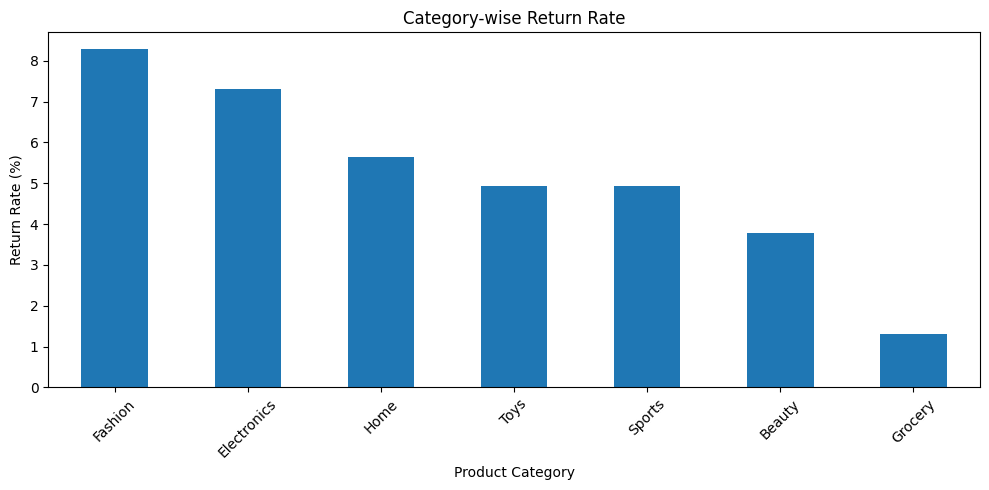

In [14]:

import matplotlib.pyplot as plt

category_returns['return_rate'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Category-wise Return Rate'
)

plt.xlabel('Product Category')
plt.ylabel('Return Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

region_returns = df_clean.groupby('region').agg(
    total_orders=('returned', 'count'),
    returned_orders=('returned', 'sum')
)

region_returns['return_rate'] = (
    region_returns['returned_orders'] /
    region_returns['total_orders']
) * 100

region_returns = region_returns.sort_values(
    by='return_rate', ascending=False
)

print(region_returns)


         total_orders  returned_orders  return_rate
region                                             
East             6904              408     5.909618
South            7584              431     5.683017
West             6808              371     5.449471
North            7572              406     5.361859
Central          5632              287     5.095881


returned
0    4.812836
1    4.837625
Name: delivery_time_days, dtype: float64


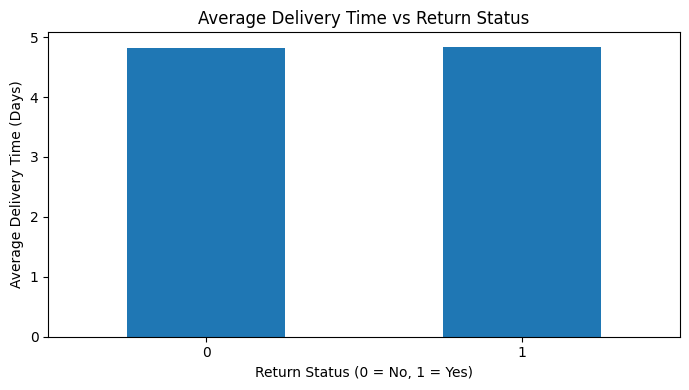

In [16]:

delivery_analysis = df_clean.groupby('returned')[
    'delivery_time_days'
].mean()

print(delivery_analysis)

delivery_analysis.plot(
    kind='bar',
    title='Average Delivery Time vs Return Status',
    figsize=(7, 4)
)

plt.xlabel('Return Status (0 = No, 1 = Yes)')
plt.ylabel('Average Delivery Time (Days)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


returned
0    0.049343
1    0.048397
Name: discount, dtype: float64


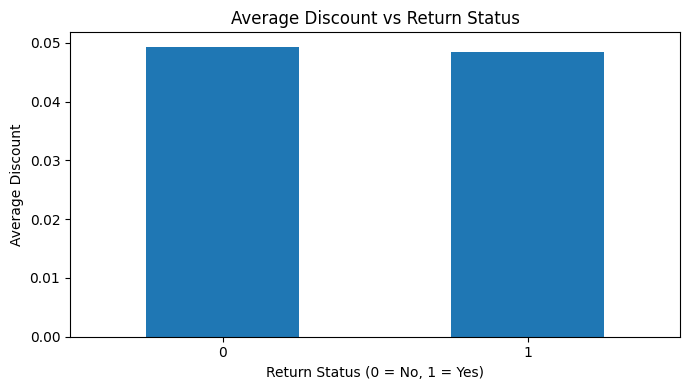

In [17]:

discount_analysis = df_clean.groupby('returned')['discount'].mean()

print(discount_analysis)

discount_analysis.plot(
    kind='bar',
    title='Average Discount vs Return Status',
    figsize=(7, 4)
)

plt.xlabel('Return Status (0 = No, 1 = Yes)')
plt.ylabel('Average Discount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

import sqlite3
import pandas as pd

# Create a SQLite database
conn = sqlite3.connect('ecommerce_returns.db')

# Transfer cleaned dataset into SQL table
df_clean.to_sql(
    'ecommerce_returns',
    conn,
    if_exists='replace',
    index=False
)

print("Dataset successfully loaded into SQL database!")


Dataset successfully loaded into SQL database!


In [19]:

query = """
SELECT *
FROM ecommerce_returns
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)

display(result)


,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender,year,month,month_name
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,2023-12-23 00:00:00,4,West,0,139.47,7.88,31.17,60,Female,2023,12,December
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,2025-04-03 00:00:00,6,South,0,24.73,4.60,-2.62,37,Male,2025,4,April
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,2024-10-08 00:00:00,4,North,0,166.80,6.58,13.44,34,Male,2024,10,October
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,2024-09-14 00:00:00,6,South,0,63.67,5.50,2.14,21,Female,2024,9,September
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,2024-12-21 00:00:00,6,East,0,13.88,2.74,1.15,39,Male,2024,12,December


In [21]:

query = """
SELECT
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(100.0 * SUM(returned) / COUNT(*), 2)
        AS return_rate
FROM ecommerce_returns;
"""

display(pd.read_sql_query(query, conn))


,total_orders,returned_orders,return_rate
0,34500,1903,5.52


In [22]:

query = """
SELECT
    category,
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(
        100.0 * SUM(returned) / COUNT(*), 2
    ) AS return_rate
FROM ecommerce_returns
GROUP BY category
ORDER BY return_rate DESC;
"""

category_sql = pd.read_sql_query(query, conn)
display(category_sql)


,category,total_orders,returned_orders,return_rate
0,Fashion,6254,518,8.28
1,Electronics,6180,451,7.30
2,Home,5487,310,5.65
3,Toys,4247,210,4.94
4,Sports,4171,206,4.94
5,Beauty,4103,155,3.78
6,Grocery,4058,53,1.31


In [23]:

query = """
SELECT
    region,
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(
        100.0 * SUM(returned) / COUNT(*), 2
    ) AS return_rate
FROM ecommerce_returns
GROUP BY region
ORDER BY return_rate DESC;
"""

region_sql = pd.read_sql_query(query, conn)
display(region_sql)


,region,total_orders,returned_orders,return_rate
0,East,6904,408,5.91
1,South,7584,431,5.68
2,West,6808,371,5.45
3,North,7572,406,5.36
4,Central,5632,287,5.10


In [24]:

query = """
SELECT
    product_id,
    category,
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(
        100.0 * SUM(returned) / COUNT(*), 2
    ) AS return_rate
FROM ecommerce_returns
GROUP BY product_id, category
HAVING COUNT(*) >= 10
ORDER BY return_rate DESC
LIMIT 10;
"""

product_sql = pd.read_sql_query(query, conn)
display(product_sql)


,product_id,category,total_orders,returned_orders,return_rate


In [25]:

query = """
SELECT
    strftime('%Y-%m', order_date) AS order_month,
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(
        100.0 * SUM(returned) / COUNT(*), 2
    ) AS return_rate
FROM ecommerce_returns
GROUP BY order_month
ORDER BY order_month;
"""

monthly_sql = pd.read_sql_query(query, conn)
display(monthly_sql)


,order_month,total_orders,returned_orders,return_rate
0,2023-09,876,39,4.45
1,2023-10,1468,74,5.04
2,2023-11,1385,73,5.27
3,2023-12,1499,84,5.60
4,2024-01,1386,74,5.34
5,2024-02,1358,68,5.01
6,2024-03,1423,92,6.47
7,2024-04,1436,91,6.34
8,2024-05,1427,77,5.40
9,2024-06,1381,66,4.78


In [26]:

query = """
SELECT
    payment_method,
    COUNT(*) AS total_orders,
    SUM(returned) AS returned_orders,
    ROUND(
        100.0 * SUM(returned) / COUNT(*), 2
    ) AS return_rate
FROM ecommerce_returns
GROUP BY payment_method
ORDER BY return_rate DESC;
"""

payment_sql = pd.read_sql_query(query, conn)
display(payment_sql)


,payment_method,total_orders,returned_orders,return_rate
0,PayPal,3444,199,5.78
1,Debit Card,8505,482,5.67
2,Credit Card,12170,675,5.55
3,UPI,4156,224,5.39
4,Wallet,2065,111,5.38
5,COD,4160,212,5.10


In [27]:

category_sql.to_csv('category_return_analysis.csv', index=False)
region_sql.to_csv('region_return_analysis.csv', index=False)
product_sql.to_csv('high_return_products_sql.csv', index=False)
monthly_sql.to_csv('monthly_return_analysis.csv', index=False)
payment_sql.to_csv('payment_return_analysis.csv', index=False)

print("All SQL analysis files exported successfully!")



All SQL analysis files exported successfully!


In [28]:

# Import machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Machine Learning libraries imported successfully!")


Machine Learning libraries imported successfully!


In [29]:

# Create model dataset
model_df = df_clean.copy()

# Convert order date
model_df['order_date'] = pd.to_datetime(
    model_df['order_date']
)

# Extract order month
model_df['order_month'] = (
    model_df['order_date'].dt.month
)

# Define input features
features = [
    'category',
    'price',
    'discount',
    'quantity',
    'payment_method',
    'region',
    'customer_age',
    'customer_gender',
    'order_month'
]

# Input variables
X = model_df[features]

# Target variable
y = model_df['returned'].astype(int)

print("Input Data Shape:", X.shape)
print("Target Data Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Input Data Shape: (34500, 9)
Target Data Shape: (34500,)

Target Distribution:
returned
0    32597
1     1903
Name: count, dtype: int64


In [30]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))


Training Records: 27600
Testing Records: 6900


In [31]:

# Identify categorical and numerical columns

categorical_features = [
    'category',
    'payment_method',
    'region',
    'customer_gender'
]

numerical_features = [
    'price',
    'discount',
    'quantity',
    'customer_age',
    'order_month'
]

# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),

        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

print("Data preprocessing setup completed!")


Data preprocessing setup completed!


In [32]:

# Create Logistic Regression pipeline

model = Pipeline(steps=[
    ('preprocessor', preprocessor),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [33]:

# Predict return status
y_pred = model.predict(X_test)

# Predict return probability
y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Return Probabilities:")
print(y_probability[:10])


Predictions completed!

First 10 Predictions:
[0 0 1 1 0 1 0 0 1 1]

First 10 Return Probabilities:
[0.49809813 0.42857615 0.50466899 0.50981346 0.45445517 0.60765033
 0.19629591 0.47272379 0.5386549  0.63511651]


In [34]:

# Calculate model performance

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(round(roc_auc_score(y_test, y_probability), 4))


Model Accuracy: 55.28 %

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.55      0.70      6519
           1       0.08      0.64      0.14       381

    accuracy                           0.55      6900
   macro avg       0.52      0.59      0.42      6900
weighted avg       0.91      0.55      0.67      6900


Confusion Matrix:
[[3572 2947]
 [ 139  242]]

ROC-AUC Score:
0.6234


In [35]:

# Create prediction results

prediction_results = pd.DataFrame({
    'product_id': model_df.loc[X_test.index, 'product_id'],
    'actual_return': y_test,
    'predicted_return': y_pred,
    'return_probability': y_probability
})

# Convert probability into percentage
prediction_results['return_risk_score'] = (
    prediction_results['return_probability'] * 100
).round(2)

# Assign risk category
prediction_results['risk_category'] = pd.cut(
    prediction_results['return_risk_score'],
    bins=[-1, 30, 60, 100],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

display(prediction_results.head(10))


,product_id,actual_return,predicted_return,return_probability,return_risk_score,risk_category
7805,P237424,0,0,0.498098,49.81,Medium Risk
9135,P234134,0,0,0.428576,42.86,Medium Risk
7664,P212863,0,1,0.504669,50.47,Medium Risk
25224,P237983,1,1,0.509813,50.98,Medium Risk
8473,P211159,0,0,0.454455,45.45,Medium Risk
23070,P231073,0,1,0.607650,60.77,High Risk
31481,P218097,0,0,0.196296,19.63,Low Risk
33201,P225409,0,0,0.472724,47.27,Medium Risk
29183,P201628,0,1,0.538655,53.87,Medium Risk
23063,P226619,0,1,0.635117,63.51,High Risk


In [36]:

# Group predictions by product

product_risk = prediction_results.groupby(
    'product_id'
).agg(
    orders_scored=('return_probability', 'count'),
    average_return_risk=('return_probability', 'mean'),
    actual_return_rate=('actual_return', 'mean')
).reset_index()

# Convert scores to percentages
product_risk['average_return_risk'] = (
    product_risk['average_return_risk'] * 100
).round(2)

product_risk['actual_return_rate'] = (
    product_risk['actual_return_rate'] * 100
).round(2)

# Select high-risk products
high_risk_products = product_risk[
    (product_risk['orders_scored'] >= 2) &
    (product_risk['average_return_risk'] >= 60)
].sort_values(
    by='average_return_risk',
    ascending=False
)

# Export CSV
high_risk_products.to_csv(
    'high_risk_products.csv',
    index=False
)

print("High-risk products exported successfully!")

display(high_risk_products.head(10))


High-risk products exported successfully!


,product_id,orders_scored,average_return_risk,actual_return_rate
6348,P249179,2,62.29,0.0
732,P205649,2,61.53,50.0
1268,P209890,2,61.24,0.0
6140,P247561,2,61.17,0.0
939,P207207,2,60.89,0.0
4916,P238022,2,60.62,0.0
2092,P216044,2,60.51,0.0
2443,P218834,2,60.45,0.0
4321,P233428,2,60.30,0.0
408,P203204,2,60.23,50.0


In [37]:

import joblib

joblib.dump(model, 'return_prediction_model.pkl')

print("Machine Learning model saved successfully!")


Machine Learning model saved successfully!


In [38]:
df_clean.to_csv('cleaned_ecommerce_data.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [39]:
prediction_results.to_csv('return_prediction_results.csv', index=False)

print("Prediction results exported successfully!")

Prediction results exported successfully!


In [40]:
high_risk_products.to_csv('high_risk_products.csv', index=False)

print("High-risk products exported successfully!")

High-risk products exported successfully!


In [41]:
from google.colab import files

files.download('cleaned_ecommerce_data.csv')
files.download('return_prediction_results.csv')
files.download('high_risk_products.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>